In [198]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt 
import seaborn as sns 
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


In [199]:
train_data = pd.read_csv('/kaggle/input/competitions/titanic/train.csv', index_col = "PassengerId")
test_data = pd.read_csv('/kaggle/input/competitions/titanic/test.csv', index_col = "PassengerId")


In [200]:
train_data.head(10)

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S


In [201]:
train_data.isnull().sum()

Survived      0
Pclass        0
Name          0
Sex           0
Age         177
SibSp         0
Parch         0
Ticket        0
Fare          0
Cabin       687
Embarked      2
dtype: int64

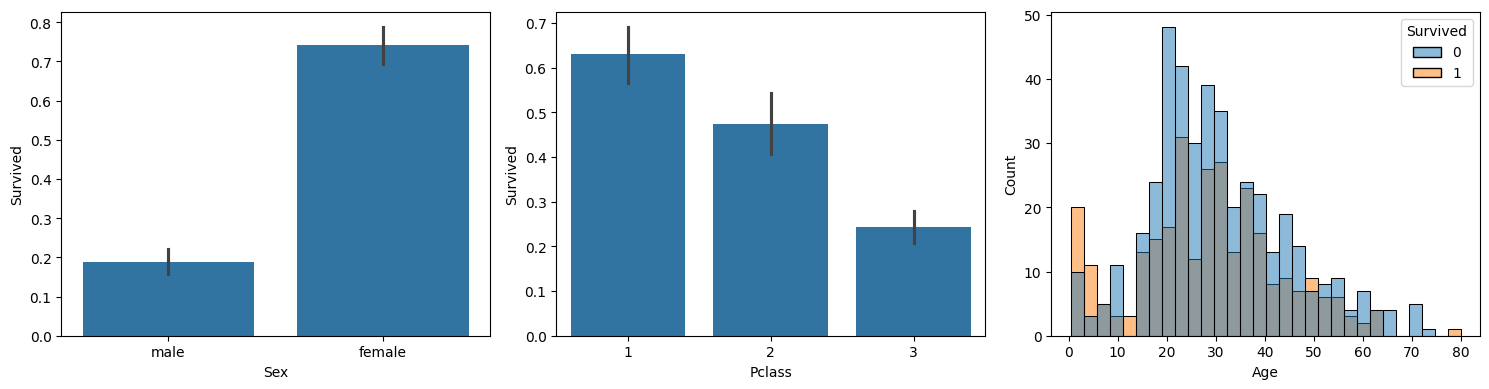

In [202]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=train_data, x='Sex', y='Survived', ax=axes[0])
sns.barplot(data=train_data, x='Pclass', y='Survived', ax=axes[1])
sns.histplot(data=train_data, x='Age', hue='Survived', bins=30, ax=axes[2])
plt.tight_layout()
plt.show()

Split Mr,miss,...


In [203]:
for i in [train_data, test_data]:
    i['Title'] = i['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
    i['Title'] = i['Title'].replace(
        ['Lady','Countess','Capt','Col','Don','Dr','Major','Rev','Sir','Jonkheer','Dona'], 'Rare')
    i['Title'] = i['Title'].replace({'Mlle':'Miss','Ms':'Miss','Mme':'Mrs'})
    

family size


In [204]:
for df in [train_data, test_data]:
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
    df['HasCabin'] = df['Cabin'].notnull().astype(int)
    df['Deck'] = df['Cabin'].str[0].fillna('U')

In [205]:
for df in [train_data, test_data]:
    df['Age'] = df['Age'].fillna(df.groupby('Title')['Age'].transform('median'))
    df['Embarked'] = df['Embarked'].fillna(train_data['Embarked'].mode()[0])
    df['Fare'] = df['Fare'].fillna(train_data['Fare'].median())

In [207]:
train_data

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,FamilySize,IsAlone,HasCabin,Deck,TicketGroup,FarePerPerson
PassengerId,,,,,,,,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr,2,0,0,U,1,7.25000
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs,2,0,1,C,2,35.64165
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Miss,1,1,0,U,1,7.92500
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Mrs,2,0,1,C,2,26.55000
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Mr,1,1,0,U,1,8.05000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,Rare,1,1,0,U,1,13.00000
888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,Miss,1,1,1,B,1,30.00000
889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,21.0,1,2,W./C. 6607,23.4500,NaN,S,Miss,4,0,0,U,4,5.86250


In [208]:
train_data.isnull().sum()

Survived           0
Pclass             0
Name               0
Sex                0
Age                0
SibSp              0
Parch              0
Ticket             0
Fare               0
Cabin            687
Embarked           0
Title              0
FamilySize         0
IsAlone            0
HasCabin           0
Deck               0
TicketGroup        0
FarePerPerson      0
dtype: int64

In [214]:


from sklearn.ensemble import RandomForestClassifier

y = train_data["Survived"]

features = ["Pclass", "Sex", "Age", "Fare", "Embarked",
            "Title", "FamilySize", "IsAlone", "HasCabin", "Deck", 
            # "TicketGroup", "FarePerPerson"
           ]

X = pd.get_dummies(train_data[features])
X_test = pd.get_dummies(test_data[features])
X_test = X_test.reindex(columns=X.columns, fill_value=0)

model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=1)
model.fit(X, y)
predictions = model.predict(X_test)

output = pd.DataFrame({'PassengerId': test_data.index, 'Survived': predictions})
output.to_csv('submission.csv', index=False)
print("Your submission was successfully saved!")



Your submission was successfully saved!


In [215]:
from sklearn.model_selection import cross_val_score
print(cross_val_score(model, X, y, cv=5).mean())

0.8316364321134895
